# Customer Churn Prediction for a Telecom Company Using Machine Learning 

Customer churn refers to a situation when a customer decides to stop using the services of a company.Customer churn is an important problem for telecom companies beacause losing existing customers can affect the company`s revenue and growth.

## PROJECT INTRODUCTION

## 1.Project Objective

The objective of this project is to analyze customer characteristics, identify patterns associated with churn, and develop a machine learning model that estimates the likelihood of a customer leaving the service.

## 2.Business Value

The analysis aims to help telecom companies identify customers who may need additional support, investigate possible reasons for churn, and design targeted customer retention strategies.

## 3.Analytical Approach

The project includes data quality assessment, exploratory data analysis, statistical validation, feature engineering, model comparison, model evaluation, and interpretation of results

## 4.Dataset Scope

This project uses a historical snapshot of customer information. The dataset supports customer-level churn classification, but it does not provide a complete sequence of dated customer events for forecasting churn over time.

## Input features

1.Gender
2.senior Citizen
3.Partner
4.Dependents
5.Phone Service
6.Multiple Lines
7.Internet Service
8.Online Security
9.Online Backup
10.Device Protection
11.Tech Support
12.Streaming TV
13.Streaming Movies
14.Paperless Biling
15.Contract
16.Payment method
17.Tenure
18.Monthly Charges
19.Total Charges

### Target variable

Churn

0 -Customer will Stay

1 -Customer will Churn


## 1.IMPORT REQUIRED LIBRARIES

In [68]:
%pip install pandas numpy matplotlib seaborn scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score
)

print("Libraries imported successfully!")

Libraries imported successfully!


## 2.Load Customer Churn Dataset

In [17]:
url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"

df = pd.read_csv(url)


print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [18]:
df = pd.read_csv(url)
print("Dataset shape:", df.shape)

print("\nDuplicate rows:", df.duplicated().sum())
print("Duplicate customer IDs:", df["customerID"].duplicated().sum())

print("\nData types:")
display(df.dtypes.to_frame("Data Type"))

print("\nMissing values:")
display(
    df.isnull().sum()
      .sort_values(ascending=False)
      .to_frame("Missing Count")
)

print("\nUnique values per column:")
display(df.nunique().to_frame("Unique Values"))

Dataset shape: (7043, 21)

Duplicate rows: 0
Duplicate customer IDs: 0

Data types:


,Data Type
customerID,str
gender,str
SeniorCitizen,int64
Partner,str
Dependents,str
tenure,int64
PhoneService,str
MultipleLines,str
InternetService,str
OnlineSecurity,str



Missing values:


,Missing Count
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0



Unique values per column:


,Unique Values
customerID,7043
gender,2
SeniorCitizen,2
Partner,2
Dependents,2
tenure,73
PhoneService,2
MultipleLines,3
InternetService,3
OnlineSecurity,3


In [72]:
print("df exists:", "df" in globals())
print("X_test exists:", "X_test" in globals())
print("y_test exists:", "y_test" in globals())

df exists: True
X_test exists: True
y_test exists: True


## Understand the dataset

In [19]:
print("Rows and columns:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types and non-null values:")
df.info()

print("\nFirst five records:")
display(df.head())

Rows and columns: (7043, 21)

Column names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Data types and non-null values:
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-n

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## clean the data

In [20]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

print("Missing values after conversion:")
print(df.isnull().sum().sort_values(ascending=False).head())

print("Duplicate customer IDs:", df["customerID"].duplicated().sum())
print("Negative tenure:", (df["tenure"] < 0).sum())
print("Negative monthly charges:", (df["MonthlyCharges"] < 0).sum())
print("Negative total charges:", (df["TotalCharges"] < 0).sum())

Missing values after conversion:
TotalCharges     11
gender            0
SeniorCitizen     0
Partner           0
customerID        0
dtype: int64
Duplicate customer IDs: 0
Negative tenure: 0
Negative monthly charges: 0
Negative total charges: 0


## Feature Engineering

In [21]:
df["AverageChargePerTenureMonth"] = (
    df["TotalCharges"] /
    df["tenure"].replace(0, np.nan)
)

df["HasMultipleServices"] = (
    (df["PhoneService"] == "Yes").astype(int)
    + (df["OnlineSecurity"] == "Yes").astype(int)
    + (df["OnlineBackup"] == "Yes").astype(int)
    + (df["DeviceProtection"] == "Yes").astype(int)
    + (df["TechSupport"] == "Yes").astype(int)
    + (df["StreamingTV"] == "Yes").astype(int)
    + (df["StreamingMovies"] == "Yes").astype(int)
)

print("Feature engineering completed!")
display(
    df[[
        "tenure",
        "TotalCharges",
        "AverageChargePerTenureMonth",
        "HasMultipleServices"
    ]].head()
)

Feature engineering completed!


,tenure,TotalCharges,AverageChargePerTenureMonth,HasMultipleServices
0,1,29.85,29.850000,1
1,34,1889.50,55.573529,3
2,2,108.15,54.075000,3
3,45,1840.75,40.905556,3
4,2,151.65,75.825000,1


## Analyze Customer Churn

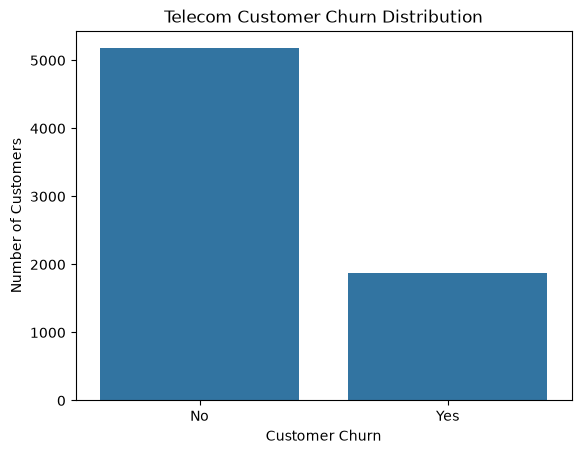

In [22]:
sns.countplot(data=df, x="Churn")
plt.title("Telecom Customer Churn Distribution")
plt.xlabel("Customer Churn")
plt.ylabel("Number of Customers")
plt.show()

In [23]:
print(df["Churn"].value_counts())

print("\nChurn percentages:")
print(
    (df["Churn"].value_counts(normalize=True) * 100).round(2)
)

Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn percentages:
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


## Analyze Churn by contract type

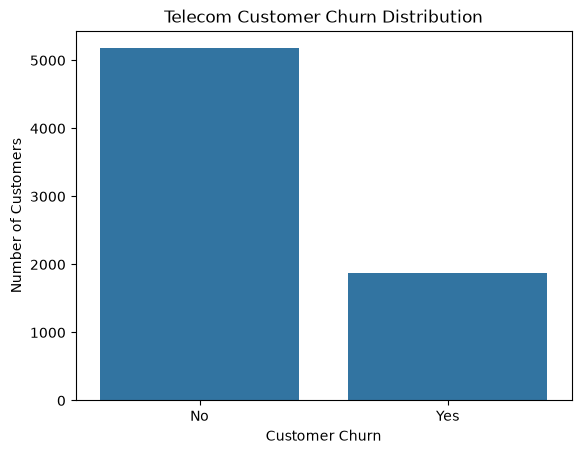

,TenureGroup,Churn Rate (%)
0,0-12 months,47.44
1,13-24 months,28.71
2,25-48 months,20.39
3,49-72 months,9.51


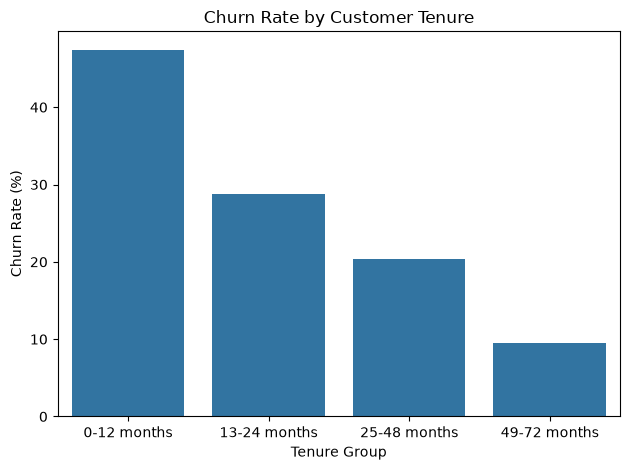

In [24]:
sns.countplot(data=df, x="Churn")
plt.title("Telecom Customer Churn Distribution")
plt.xlabel("Customer Churn")
plt.ylabel("Number of Customers")
plt.show()
df["TenureGroup"] = pd.cut(
    df["tenure"],
    bins=[-1, 12, 24, 48, 72],
    labels=["0-12 months", "13-24 months",
            "25-48 months", "49-72 months"]
)

tenure_churn = (
    df.groupby("TenureGroup", observed=False)["Churn"]
      .apply(lambda s: (s == "Yes").mean() * 100)
      .reset_index(name="Churn Rate (%)")
)

display(tenure_churn.round(2))

sns.barplot(
    data=tenure_churn,
    x="TenureGroup",
    y="Churn Rate (%)"
)

plt.title("Churn Rate by Customer Tenure")
plt.ylabel("Churn Rate (%)")
plt.xlabel("Tenure Group")
plt.tight_layout()
plt.show()

In [25]:
import seaborn as sns
import matplotlib.pyplot as plt

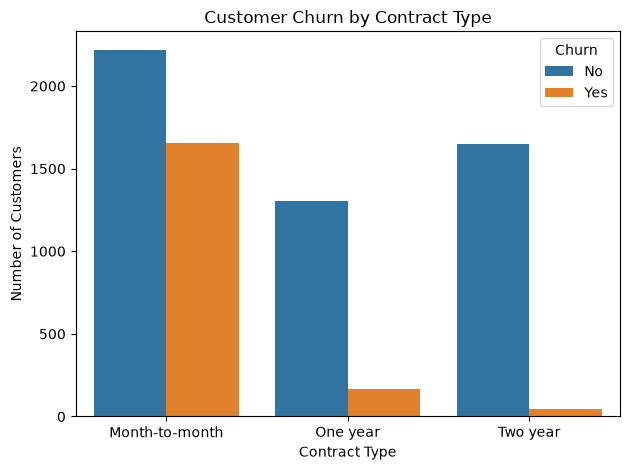

PaymentMethod
Electronic check             45.29
Mailed check                 19.11
Bank transfer (automatic)    16.71
Credit card (automatic)      15.24
Name: Churn, dtype: float64

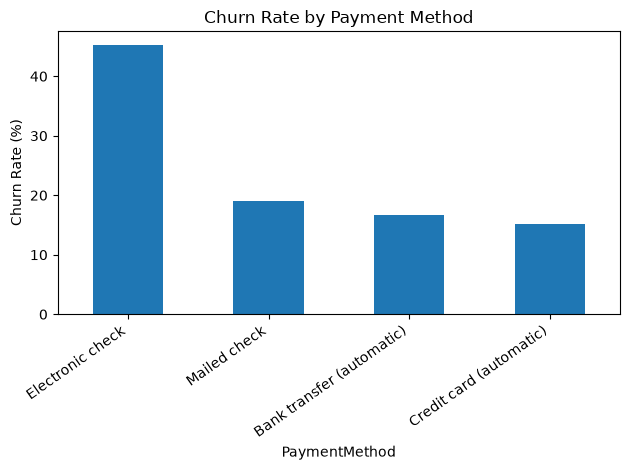

In [26]:
sns.countplot(data=df, x="Contract", hue="Churn")
plt.title("Customer Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()
payment_churn = (
    df.groupby("PaymentMethod")["Churn"]
      .apply(lambda s: (s == "Yes").mean() * 100)
      .sort_values(ascending=False)
)

display(payment_churn.round(2))

payment_churn.plot(kind="bar")
plt.title("Churn Rate by Payment Method")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

## statistical Validation

In [27]:
from scipy.stats import chi2_contingency

contingency_table = pd.crosstab(
    df["Contract"],
    df["Churn"]
)

chi2, p_value, dof, expected = chi2_contingency(
    contingency_table
)

print("Chi-square statistic:", round(chi2, 3))
print("Degrees of freedom:", dof)
print("P-value:", p_value)

if p_value < 0.05:
    print("Statistically significant association detected.")
else:
    print("Insufficient evidence of an association.")

Chi-square statistic: 1184.597
Degrees of freedom: 2
P-value: 5.863038300673391e-258
Statistically significant association detected.


## Separate input features and target

In [28]:
X = df.drop(columns=["Churn", "customerID"])

y = df["Churn"].map({
    "No": 0,
    "Yes": 1
})

numeric_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=["number"]
).columns.tolist()

print("Input features:", X.shape[1])
print("Numeric features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

Input features: 22
Numeric features: 6
Categorical features: 16


## Split the datset

In [29]:

X = df.drop(columns=["Churn", "customerID"])

y = df["Churn"].map({"No": 0, "Yes": 1})

print("Features and target created successfully!")
print("X shape:", X.shape)
print("y shape:", y.shape)


Features and target created successfully!
X shape: (7043, 22)
y shape: (7043,)


In [30]:
from sklearn.model_selection import train_test_split
print("train_test_split imported successfully")

train_test_split imported successfully


In [31]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20,random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 5634
Testing records: 1409


In [32]:
numerical_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool","str"]
).columns.tolist()

print("Numerical features:", numerical_features)
print("Categorical features:", categorical_features)

Numerical features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'AverageChargePerTenureMonth', 'HasMultipleServices']
Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'TenureGroup']


## Prepare the preprocessing pipeline

In [33]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

In [34]:

numeric_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=["number"]
).columns.tolist()

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)


Numeric features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'AverageChargePerTenureMonth', 'HasMultipleServices']
Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'TenureGroup']


In [36]:
numerical_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool","str"]
).columns.tolist()

print("Numerical features:", numerical_features)
print("Categorical features:", categorical_features)

Numerical features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'AverageChargePerTenureMonth', 'HasMultipleServices']
Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'TenureGroup']


In [37]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("Preprocessing pipeline created!")

Preprocessing pipeline created!


## Train the Random Forest Model

In [38]:
print("X_train columns:")
print(X_train.columns.tolist())

print("\nNumerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)

X_train columns:
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'AverageChargePerTenureMonth', 'HasMultipleServices', 'TenureGroup']

Numerical features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'AverageChargePerTenureMonth', 'HasMultipleServices']

Categorical features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'TenureGroup']


In [40]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced"
    ))
])

model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [92]:
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced"
    ))
])

model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


## Evaluate the model

In [41]:
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

print("Accuracy:", round(accuracy_score(y_test, y_pred), 3))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Stayed", "Churned"],
    zero_division=0
))

print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 3))

Accuracy: 0.764

Classification Report:
              precision    recall  f1-score   support

      Stayed       0.86      0.81      0.83      1035
     Churned       0.55      0.64      0.59       374

    accuracy                           0.76      1409
   macro avg       0.70      0.72      0.71      1409
weighted avg       0.78      0.76      0.77      1409

ROC-AUC: 0.822


## Add a baseline Model

In [42]:

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.base import clone
from sklearn.preprocessing import StandardScaler


In [43]:

numeric_features = X_train.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=["number"]).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler",StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("Preprocessor created successfully!")


Preprocessor created successfully!


In [44]:
from sklearn.metrics import recall_score

In [45]:
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate

baseline_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", DummyClassifier(strategy="most_frequent"))
])

baseline_model.fit(X_train, y_train)

baseline_pred = baseline_model.predict(X_test)

print(
    "Baseline accuracy:",
    round(accuracy_score(y_test, baseline_pred), 3)
)

print(
    "Baseline churn recall:",
    round(recall_score(y_test, baseline_pred, zero_division=0), 3)
)

Baseline accuracy: 0.735
Baseline churn recall: 0.0


## Create a confusion matrix

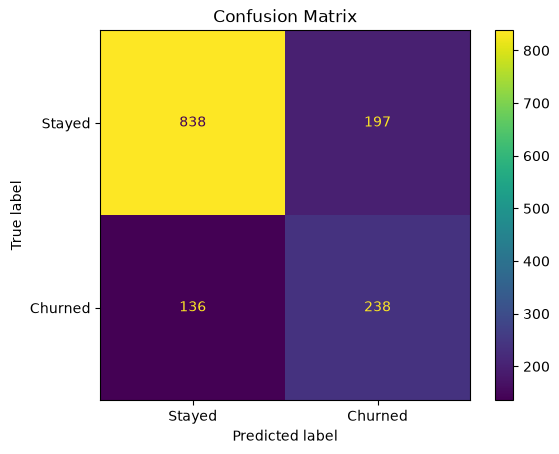

In [46]:
cm = confusion_matrix(y_test, y_pred)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Stayed", "Churned"]
).plot()

plt.title("Confusion Matrix")
plt.show()

## Find the most important Features

In [47]:
feature_names = (
    model.named_steps["preprocessor"]
    .get_feature_names_out()
)

importances = (
    model.named_steps["classifier"].feature_importances_
)

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values("Importance", ascending=False)

display(importance_df.head(10))

,Feature,Importance
3,numeric__TotalCharges,0.109878
1,numeric__tenure,0.100490
4,numeric__AverageChargePerTenureMonth,0.097669
2,numeric__MonthlyCharges,0.095763
38,categorical__Contract_Month-to-month,0.076531
20,categorical__OnlineSecurity_No,0.032817
29,categorical__TechSupport_No,0.028888
18,categorical__InternetService_Fiber optic,0.027357
40,categorical__Contract_Two year,0.025964
45,categorical__PaymentMethod_Electronic check,0.024147


## Model Interpretability

Feature importance is used to identify the customer attributes that contribute most to the Random Forest model's predictions. The results will be examined alongside exploratory and statistical findings to determine whether the patterns are commercially plausible.

Feature importance measures predictive contribution, not causation. Important features will therefore be interpreted cautiously, and conclusions will be limited to the available dataset.

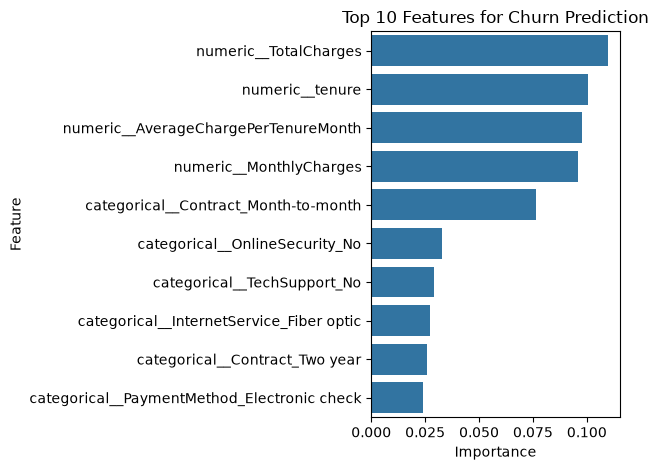

In [48]:
sns.barplot(
    data=importance_df.head(10),
    x="Importance",
    y="Feature"
)

plt.title("Top 10 Features for Churn Prediction")
plt.tight_layout()
plt.show()

## Predict the Customers Churn

In [49]:
sample_customer = X_test.iloc[[0]]

prediction = model.predict(sample_customer)[0]
probability = model.predict_proba(sample_customer)[0, 1]

print("Predicted churn:", "Yes" if prediction == 1 else "No")
print("Estimated churn probability:", round(probability * 100, 2), "%")

Predicted churn: No
Estimated churn probability: 0.0 %


In [50]:
from sklearn.base import clone

In [51]:
import sklearn.base
print(sklearn.base.clone)

<function clone at 0x00000189BA405C60>


## Train a Logistic Regression Model

In [52]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=5000,
        class_weight="balanced"
    ))
])

logistic_model.fit(X_train, y_train)

print("Logistic Regression model trained!")

Logistic Regression model trained!


In [53]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=5000,
        class_weight="balanced"
    ))
])

logistic_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [54]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

import pandas as pd
from IPython.display import display

## Compare both models

In [55]:
models = {
    "Logistic Regression": logistic_model,
    "Random Forest": model
}

results = []

for name, clf in models.items():
    pred = clf.predict(X_test)
    prob = clf.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1 Score": f1_score(y_test, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, prob)
    })

results_df = pd.DataFrame(results)
display(results_df.round(3))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.734,0.499,0.794,0.613,0.842
1,Random Forest,0.764,0.547,0.636,0.588,0.822


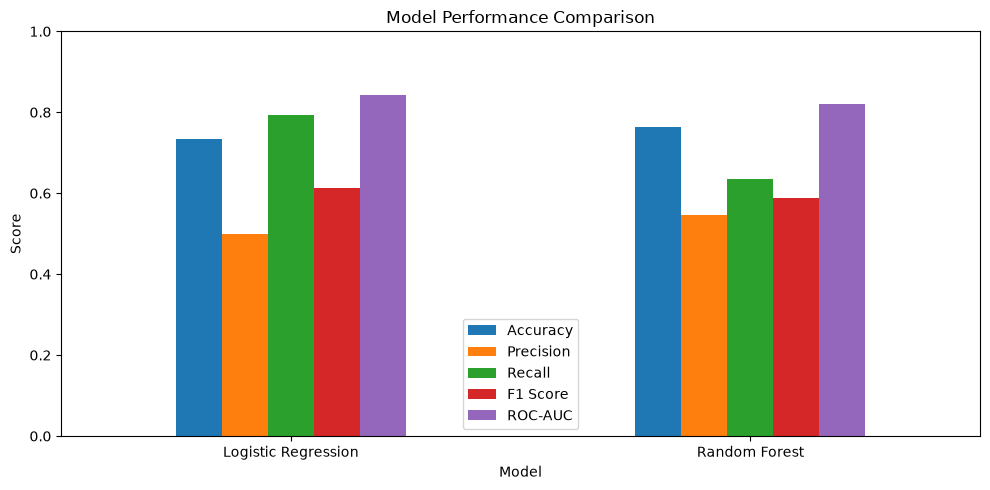

In [56]:
results_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"]
].plot(kind="bar", figsize=(10, 5))

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Add Cross Validation

In [58]:
from sklearn.model_selection import StratifiedKFold, cross_validate

In [59]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

cv_results = cross_validate(
    model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

for metric in scoring:
    scores = cv_results[f"test_{metric}"]
    print(
        f"{metric}: {scores.mean():.3f} "
        f"+/- {scores.std():.3f}"
    )

accuracy: 0.779 +/- 0.013
precision: 0.574 +/- 0.022
recall: 0.643 +/- 0.034
f1: 0.607 +/- 0.027
roc_auc: 0.829 +/- 0.010


In [60]:
%pip install openpyxl

Note: you may need to restart the kernel to use updated packages.


In [61]:
import openpyxl
print("openpyxl installed successfully!")

openpyxl installed successfully!


## Export predictions to Excel

In [62]:
import pandas as pd
print ("pandas imported successfully!")

pandas imported successfully!


In [63]:
customer_results = pd.DataFrame({
    "CustomerID": df.loc[X_test.index, "customerID"],
    "Actual Churn": y_test.map({0: "No", 1: "Yes"}),
    "Predicted Churn": pd.Series(
        model.predict(X_test),
        index=X_test.index
    ).map({0: "No", 1: "Yes"}),
    "Churn Probability (%)": (
        model.predict_proba(X_test)[:, 1] * 100
    ).round(2)
})

customer_results = customer_results.sort_values(
    "Churn Probability (%)",
    ascending=False
)

customer_results.to_excel(
    "telecom_churn_predictions.xlsx",
    index=False
)

display(customer_results.head(10))
print("Excel predictions saved successfully!")

,CustomerID,Actual Churn,Predicted Churn,Churn Probability (%)
6633,4415-IJZTP,Yes,Yes,100.0
2927,5542-TBBWB,No,Yes,100.0
1731,8375-DKEBR,Yes,Yes,100.0
1144,0841-NULXI,Yes,Yes,100.0
1739,9804-ICWBG,Yes,Yes,100.0
2194,2514-GINMM,Yes,Yes,100.0
809,1820-TQVEV,Yes,Yes,99.5
6623,9248-OJYKK,Yes,Yes,99.5
3682,3716-BDVDB,Yes,Yes,99.5
5706,5196-SGOAK,Yes,Yes,98.5


Excel predictions saved successfully!


In [64]:
import joblib
print("Joblib imported successfully!")

Joblib imported successfully!


## Limitations

1.The analysis uses a public sample dataset and may not represent every telecom company's customer base.

2.The dataset contains a customer snapshot rather than a full dated history of customer events.

3.The observed associations do not prove causation.

4.Model performance may change when applied to new customers or different business environments.

5.Churn predictions are estimates and should not be treated as certain outcomes.

## Temporal Analysis

A time-based validation strategy cannot be properly implemented using this dataset alone because it does not provide the required dated customer history. The project therefore uses stratified train-test splitting and cross-validation. A production-ready model should be evaluated using historical customer records and a time-based holdout that reflects the intended prediction date.

## Conclusion 

The project investigates telecom customer churn using exploratory analysis, statistical testing, feature engineering, and machine learning. Model performance is assessed against a baseline using appropriate classification metrics. The findings can help identify customer groups for further investigation and inform retention experiments.

## Save the model and display the final summary

In [65]:
joblib.dump(model, "telecom_churn_model.pkl")

print("Trained model saved successfully!")

Trained model saved successfully!


In [66]:
loaded_model = joblib.load("telecom_churn_model.pkl")

print("Saved model loaded successfully!")

Saved model loaded successfully!


## Project Summary

In [67]:
best_model = results_df.loc[
    results_df["F1 Score"].idxmax()
]

print("=" * 45)
print("TELECOM CUSTOMER CHURN PREDICTION")
print("=" * 45)

print("Total customers:", len(df))
print("Input features:", X.shape[1])
print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Best model by F1-score:", best_model["Model"])
print("F1-score:", round(best_model["F1 Score"], 3))
print("ROC-AUC:", round(best_model["ROC-AUC"], 3))
print("=" * 45)

TELECOM CUSTOMER CHURN PREDICTION
Total customers: 7043
Input features: 22
Training records: 5634
Testing records: 1409
Best model by F1-score: Logistic Regression
F1-score: 0.613
ROC-AUC: 0.842
